Getting the dimensions, and customer churn distribution.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import classification_report, confusion_matrix

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

df = pd.read_csv(url)

print("Dataset successfully loaded!")

Dataset successfully loaded!


In [ ]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 7043
Number of columns: 21


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [ ]:
print(df['Churn'].value_counts())

print("\nChurn percentages:")
print(df['Churn'].value_counts(normalize=True) * 100)

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn percentages:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


Data quality investigatigation

In [ ]:
print("Missing values per column:\n")
print(df.isnull().sum().sort_values(ascending=False))

Missing values per column:

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [ ]:
df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'],
    errors='coerce'
)

print("Missing TotalCharges:", df['TotalCharges'].isnull().sum())

df[df['TotalCharges'].isnull()][
    ['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges']
]

Missing TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,NaN
753,3115-CZMZD,0,20.25,NaN
936,5709-LVOEQ,0,80.85,NaN
1082,4367-NUYAO,0,25.75,NaN
1340,1371-DWPAZ,0,56.05,NaN
3331,7644-OMVMY,0,19.85,NaN
3826,3213-VVOLG,0,25.35,NaN
4380,2520-SGTTA,0,20.00,NaN
5218,2923-ARZLG,0,19.70,NaN
6670,4075-WKNIU,0,73.35,NaN


In [ ]:
print("Duplicate rows:", df.duplicated().sum())

print("Duplicate customer IDs:", df['customerID'].duplicated().sum())

Duplicate rows: 0
Duplicate customer IDs: 0


In [ ]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7032.000000
mean,0.162147,32.371149,64.761692,2283.300441
std,0.368612,24.559481,30.090047,2266.771362
min,0.000000,0.000000,18.250000,18.800000
25%,0.000000,9.000000,35.500000,401.450000
50%,0.000000,29.000000,70.350000,1397.475000
75%,0.000000,55.000000,89.850000,3794.737500
max,1.000000,72.000000,118.750000,8684.800000


In [ ]:
for column in df.select_dtypes(include='object').columns:
    print(f"\n{column}:")
    print(df[column].unique())



customerID:
['7590-VHVEG' '5575-GNVDE' '3668-QPYBK' ... '4801-JZAZL' '8361-LTMKD'
 '3186-AJIEK']

gender:
['Female' 'Male']

Partner:
['Yes' 'No']

Dependents:
['No' 'Yes']

PhoneService:
['No' 'Yes']

MultipleLines:
['No phone service' 'No' 'Yes']

InternetService:
['DSL' 'Fiber optic' 'No']

OnlineSecurity:
['No' 'Yes' 'No internet service']

OnlineBackup:
['Yes' 'No' 'No internet service']

DeviceProtection:
['No' 'Yes' 'No internet service']

TechSupport:
['No' 'Yes' 'No internet service']

StreamingTV:
['No' 'Yes' 'No internet service']

StreamingMovies:
['No' 'Yes' 'No internet service']

Contract:
['Month-to-month' 'One year' 'Two year']

PaperlessBilling:
['Yes' 'No']

PaymentMethod:
['Electronic check' 'Mailed check' 'Bank transfer (automatic)'
 'Credit card (automatic)']

Churn:
['No' 'Yes']


**Data quality findings**

11 missing values identified

All 11 missing TotalCharges records have something in common:
- tenure = 0
- They are newly registered customers.
- They have a valid MonthlyCharges.
- Their TotalCharges haven't been recorded yet.


No duplicates.




Dataset cleaning

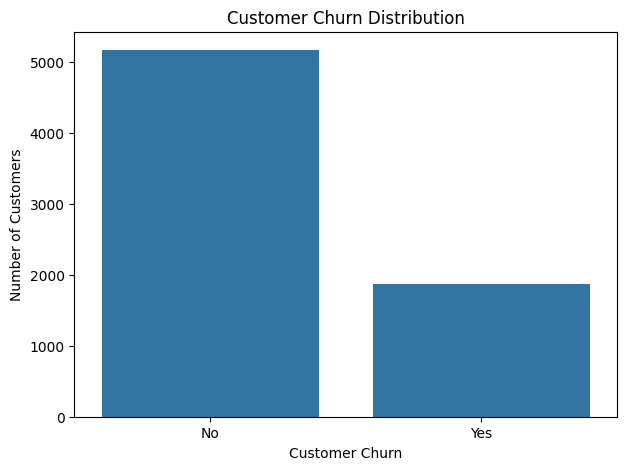

In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='Churn')

plt.title('Customer Churn Distribution')
plt.xlabel('Customer Churn')
plt.ylabel('Number of Customers')

plt.show()

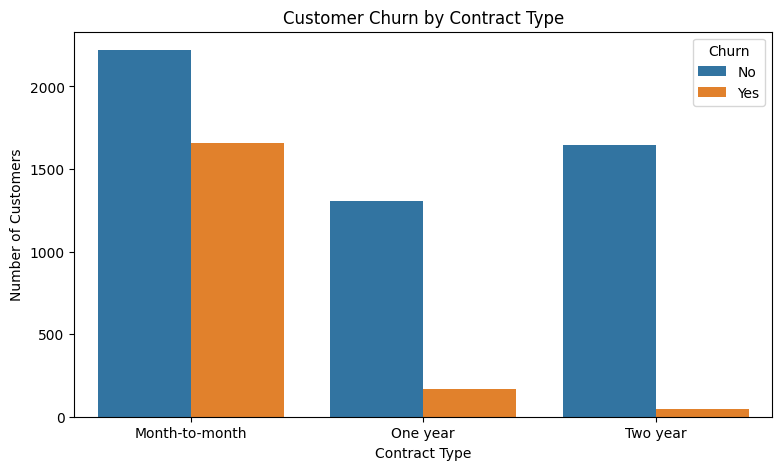

In [ ]:
plt.figure(figsize=(9, 5))

sns.countplot(data=df, x='Contract', hue='Churn')

plt.title('Customer Churn by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Number of Customers')

plt.show()

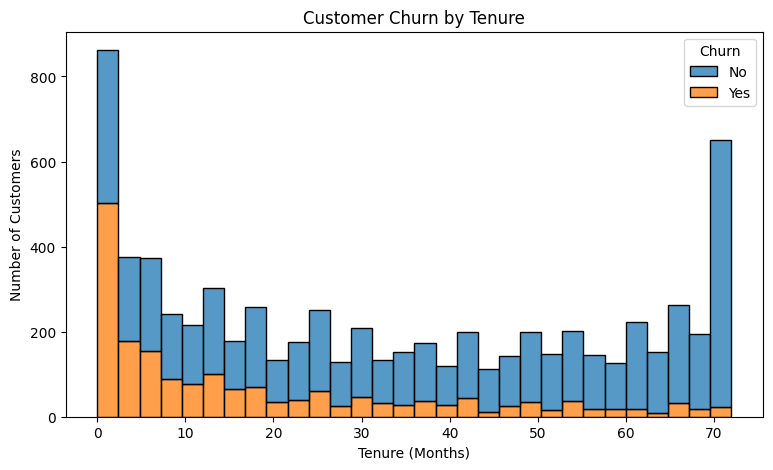

In [ ]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x='tenure',
    hue='Churn',
    bins=30,
    multiple='stack'
)

plt.title('Customer Churn by Tenure')
plt.xlabel('Tenure (Months)')
plt.ylabel('Number of Customers')

plt.show()

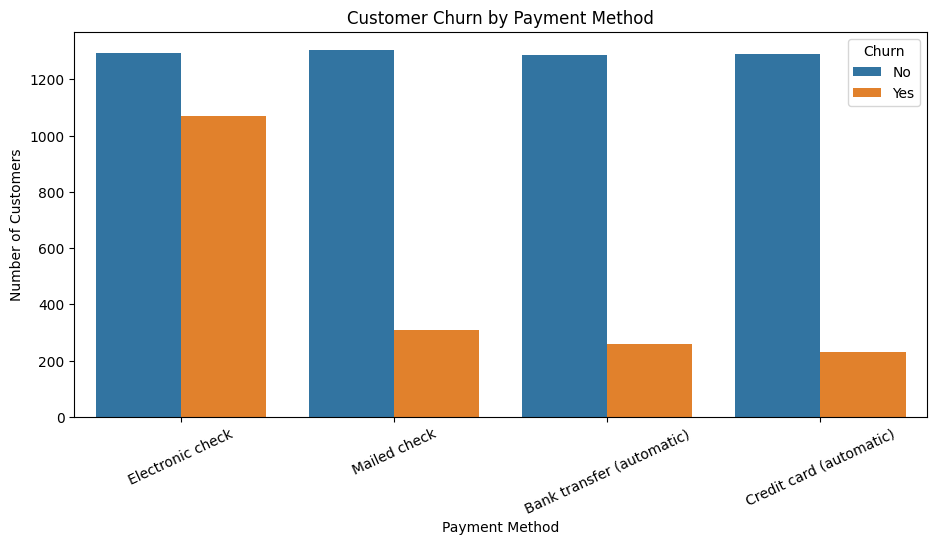

In [ ]:
plt.figure(figsize=(11, 5))

sns.countplot(
    data=df,
    x='PaymentMethod',
    hue='Churn'
)

plt.title('Customer Churn by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Number of Customers')

plt.xticks(rotation=25)

plt.show()

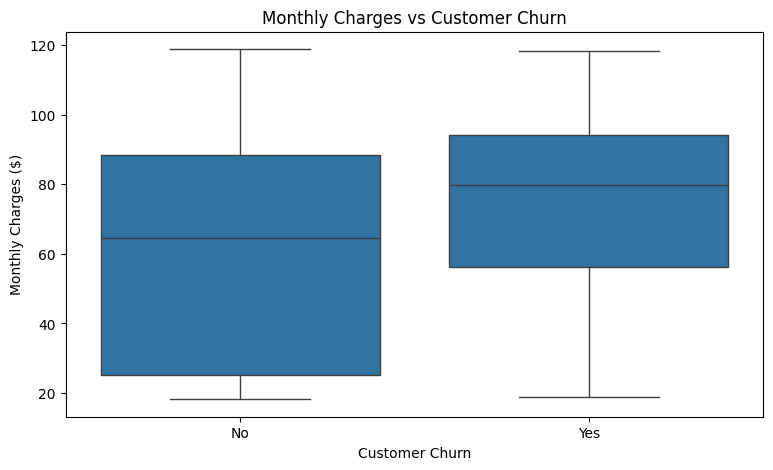

In [ ]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x='Churn',
    y='MonthlyCharges'
)

plt.title('Monthly Charges vs Customer Churn')
plt.xlabel('Customer Churn')
plt.ylabel('Monthly Charges ($)')

plt.show()

**EDA Findings**

Finding 1 (Overall churn)
- 5,174 customers stayed.
- 1,869 customers left.
- Churn rate: 26.54%


Finding 2 (Churn by customer type)

- Month-to-month customers account
for the largest number of churned customers.

- One-year contract customers have considerably fewer churns.

- Two-year contract customers have very few churns.



Finding 3 (Tenure histogram)

- New customers have a high concentration of churn.

- Churn appears particularly common during the first few months.

- Long-standing customers appear more likely to remain.


Finding 4 (Churn by payment)

- Electronic cheque customers appear to account for the highest number of churned customers.

- The other payment methods have considerably fewer churned customers.

- The company could investigate whether electronic cheque users experience payment friction or have different customer characteristics.
- These are raw counts, not churn rates. We need to account for the number of customers using each payment method before drawing conclusions.


Finding 5 (Monthly charges vs churn)

- Customers who stayed have a median monthly charge of approximately $65.

- Customers who churned have a median around $80.

Calculation of churn rates

In [ ]:
categories = [
    'Contract',
    'PaymentMethod',
    'InternetService',
    'TechSupport',
    'OnlineSecurity',
    'PaperlessBilling'
]

for column in categories:

    churn_rate = (
        df.groupby(column)['Churn']
        .apply(lambda x: (x == 'Yes').mean() * 100)
        .sort_values(ascending=False)
    )

    print(f"\nChurn Rate by {column}:")
    print(churn_rate.round(2))


Churn Rate by Contract:
Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn, dtype: float64

Churn Rate by PaymentMethod:
PaymentMethod
Electronic check             45.29
Mailed check                 19.11
Bank transfer (automatic)    16.71
Credit card (automatic)      15.24
Name: Churn, dtype: float64

Churn Rate by InternetService:
InternetService
Fiber optic    41.89
DSL            18.96
No              7.40
Name: Churn, dtype: float64

Churn Rate by TechSupport:
TechSupport
No                     41.64
Yes                    15.17
No internet service     7.40
Name: Churn, dtype: float64

Churn Rate by OnlineSecurity:
OnlineSecurity
No                     41.77
Yes                    14.61
No internet service     7.40
Name: Churn, dtype: float64

Churn Rate by PaperlessBilling:
PaperlessBilling
Yes    33.57
No     16.33
Name: Churn, dtype: float64


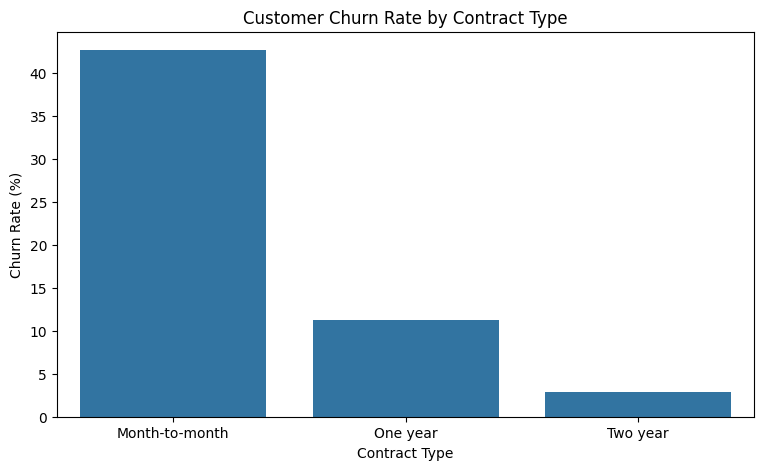

In [ ]:
contract_churn = (
    df.groupby('Contract')['Churn']
    .apply(lambda x: (x == 'Yes').mean() * 100)
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=contract_churn.index,
    y=contract_churn.values
)

plt.title('Customer Churn Rate by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Churn Rate (%)')

plt.show()

Preliminary Exploratory Data Analysis Findings

1. Contract Type

Month-to-month customers have a churn rate of 42.71%, compared with 11.27% for one-year contracts and 2.83% for two-year contracts.

Insight: Contract duration is strongly associated with customer retention.



2. Payment Method

Electronic cheque customers have the highest churn rate at 45.29%.

Insight: Payment method may be a useful predictor of customer churn.



3. Internet Service

Fiber optic customers have a churn rate of 41.89%, compared with 18.96% for DSL customers.

Insight: Internet service type is associated with differences in customer retention.



4. Additional Services

Customers without technical support and online security have substantially higher churn rates.

Insight: Additional service subscriptions may be associated with improved customer retention.



5. Paperless Billing

Customers using paperless billing have a churn rate of 33.57%, compared with 16.33% for customers without paperless billing.

Insight: Billing preferences may provide additional predictive information.



Overall Conclusion

Contract type, payment method, internet service and additional support services show promising relationships with customer churn.

These are preliminary associations, not evidence of causation. Further statistical analysis and machine learning will help establish their predictive usefulness.

Investigatiion of customer tenure before preprocessing and training

In [ ]:
# Create customer tenure groups

df['TenureGroup'] = pd.cut(
    df['tenure'],
    bins=[-1, 12, 24, 48, 60, 72],
    labels=[
        'New (0-12 months)',
        'Developing (13-24 months)',
        'Established (25-48 months)',
        'Long-term (49-60 months)',
        'Loyal (61-72 months)'
    ]
)




In [ ]:

# Calculate churn rate for each group

tenure_churn = (
    df.groupby('TenureGroup', observed=False)['Churn']
    .apply(lambda x: (x == 'Yes').mean() * 100)
)

print("Churn Rate by Customer Tenure:")
print(tenure_churn.round(2))

Churn Rate by Customer Tenure:
TenureGroup
New (0-12 months)             47.44
Developing (13-24 months)     28.71
Established (25-48 months)    20.39
Long-term (49-60 months)      14.42
Loyal (61-72 months)           6.61
Name: Churn, dtype: float64


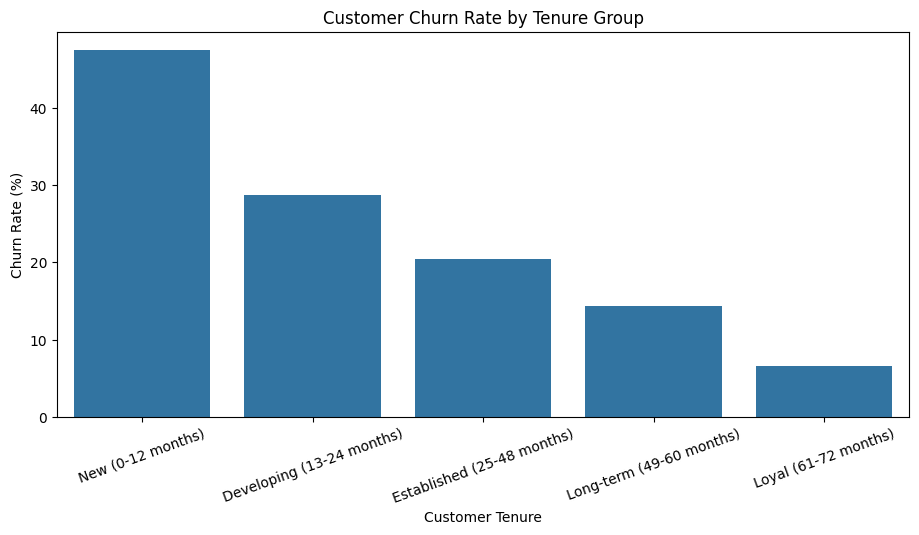

In [ ]:
plt.figure(figsize=(11, 5))

sns.barplot(
    x=tenure_churn.index,
    y=tenure_churn.values
)

plt.title('Customer Churn Rate by Tenure Group')
plt.xlabel('Customer Tenure')
plt.ylabel('Churn Rate (%)')

plt.xticks(rotation=20)
plt.show()

Preparing the dataset for machine learning.

In [ ]:
X = df.drop(
    columns=['customerID', 'Churn', 'TenureGroup']
)

y = df['Churn'].map({
    'No': 0,
    'Yes': 1
})

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Features shape: (7043, 19)
Target shape: (7043,)

Target distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

Training features: (5634, 19)
Testing features: (1409, 19)

Training target distribution:
Churn
0    0.734647
1    0.265353
Name: proportion, dtype: float64

Testing target distribution:
Churn
0    0.734564
1    0.265436
Name: proportion, dtype: float64


In [ ]:
numerical_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object']
).columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

print("\nNumber of numerical features:", len(numerical_features))
print("Number of categorical features:", len(categorical_features))

Numerical features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Number of numerical features: 4
Number of categorical features: 15


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

# Numerical preprocessing
numerical_transformer = Pipeline(
    steps=[
        ('scaler', StandardScaler())
    ]
)

# Categorical preprocessing
categorical_transformer = Pipeline(
    steps=[
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ]
)

In [ ]:
# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [ ]:
# Fit on training data and transform both datasets

X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Training data after preprocessing:", X_train_processed.shape)

print("Testing data after preprocessing:", X_test_processed.shape)

Training data after preprocessing: (5634, 45)
Testing data after preprocessing: (1409, 45)


Training the machine learning models

In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Numerical preprocessing
numerical_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]
)

# Categorical preprocessing
categorical_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ]
)

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("Improved preprocessing pipeline created!")

Improved preprocessing pipeline created!


In [ ]:
models = {
    'Logistic Regression': LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    'Decision Tree': DecisionTreeClassifier(
        random_state=42
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ),

    'XGBoost': XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric='logloss',
        random_state=42,
        n_jobs=-1
    )
}

print("Four machine learning models configured")

Four machine learning models configured


In [ ]:
# Check missing values in training data

print("Missing values in X_train:")

print(
    X_train.isnull()
    .sum()
    .sort_values(ascending=False)
)

Missing values in X_train:
TotalCharges        8
SeniorCitizen       0
gender              0
Partner             0
Dependents          0
PhoneService        0
tenure              0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
MultipleLines       0
DeviceProtection    0
TechSupport         0
StreamingMovies     0
StreamingTV         0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
dtype: int64


In [ ]:
results = []

trained_models = {}

for name, model in models.items():

    # Create preprocessing + model pipeline
    pipeline = Pipeline([
        ('preprocessor', clone(preprocessor)),
        ('classifier', model)
    ])

    # Train model
    pipeline.fit(X_train, y_train)

    # Predictions
    y_pred = pipeline.predict(X_test)

    # Probability predictions
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    # Evaluate
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1 Score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_prob)
    })

    trained_models[name] = pipeline

    print(f"{name} trained successfully!")

# Create comparison table
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by='ROC-AUC',
    ascending=False
)

print("\nMODEL PERFORMANCE COMPARISON")

display(
    results_df.style.format({
        'Accuracy': '{:.4f}',
        'Precision': '{:.4f}',
        'Recall': '{:.4f}',
        'F1 Score': '{:.4f}',
        'ROC-AUC': '{:.4f}'
    })
)

Logistic Regression trained successfully!
Decision Tree trained successfully!
Random Forest trained successfully!
XGBoost trained successfully!

MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.8055,0.6572,0.5588,0.6040,0.8419
3,XGBoost,0.7984,0.6510,0.5187,0.5774,0.8410
2,Random Forest,0.7786,0.6062,0.4733,0.5315,0.8171
1,Decision Tree,0.7289,0.4896,0.5053,0.4974,0.6573


**Metrics description**

Accuracy (80.55%) – the model correctly classified around 81% of customers overall.

Precision (65.72%) – when the model predicts a customer will leave, it is correct around 66% of the time.

Recall (55.88%) – it identifies around 56% of all customers who actually leave.

F1 (60.40%) – balances precision and recall.

ROC-AUC (84.19%) – measures how well the model distinguishes customers who leave from those who stay across different classification thresholds.

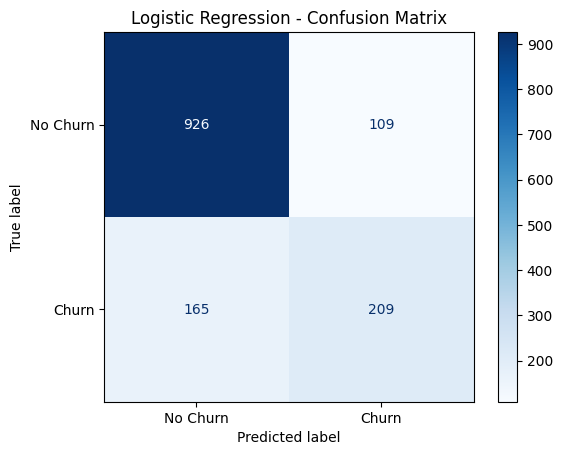

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

best_model = trained_models['Logistic Regression']

y_pred = best_model.predict(X_test)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=['No Churn', 'Churn'],
    cmap='Blues'
)

plt.title('Logistic Regression - Confusion Matrix')
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

# Split the original training data into training and validation sets
X_train_new, X_val, y_train_new, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

# Train Logistic Regression on the smaller training set
validation_model = clone(trained_models['Logistic Regression'])

validation_model.fit(X_train_new, y_train_new)

# Get churn probabilities for validation customers
y_val_prob = validation_model.predict_proba(X_val)[:, 1]

print("Validation model trained successfully!")

Validation model trained successfully!


In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.3, 0.35, 0.4, 0.45, 0.5]

for threshold in thresholds:
    y_val_pred = (y_val_prob >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")
    print("Precision:", round(precision_score(y_val, y_val_pred), 4))
    print("Recall:", round(recall_score(y_val, y_val_pred), 4))
    print("F1 Score:", round(f1_score(y_val, y_val_pred), 4))


Threshold: 0.3
Precision: 0.5433
Recall: 0.7559
F1 Score: 0.6322

Threshold: 0.35
Precision: 0.5808
Recall: 0.709
F1 Score: 0.6386

Threshold: 0.4
Precision: 0.6173
Recall: 0.6689
F1 Score: 0.6421

Threshold: 0.45
Precision: 0.6593
Recall: 0.602
F1 Score: 0.6294

Threshold: 0.5
Precision: 0.6936
Recall: 0.5452
F1 Score: 0.6105


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Use our Logistic Regression model trained on the full training set
best_model = trained_models['Logistic Regression']

# Predict probabilities on the untouched test set
y_test_prob = best_model.predict_proba(X_test)[:, 1]

# Apply our selected threshold
chosen_threshold = 0.40
y_test_improved = (y_test_prob >= chosen_threshold).astype(int)

# Evaluate performance
print("IMPROVED LOGISTIC REGRESSION MODEL")
print("Threshold:", chosen_threshold)
print("Accuracy:", round(accuracy_score(y_test, y_test_improved), 4))
print("Precision:", round(precision_score(y_test, y_test_improved), 4))
print("Recall:", round(recall_score(y_test, y_test_improved), 4))
print("F1 Score:", round(f1_score(y_test, y_test_improved), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_test_prob), 4))

# Display confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_improved,
    display_labels=['No Churn', 'Churn'],
    cmap='Blues'
)

plt.title('Improved Logistic Regression - Threshold 0.40')
plt.show()